# Lab: clustering 178 wines

Companion notebook of the lesson *U2 Clustering* — https://insper.github.io/ML/2026.2/classes/clustering/

178 wines from three cultivars, clustered without looking at the cultivar. The **fundamental lab** (steps 1 to 6) scales the data, chooses k, compares with shuffled data and profiles the clusters; the **advanced lab** (steps 7 to 9) tries DBSCAN and HDBSCAN, looks through PCA and only at the end audits every decision against the true cultivars. Runs in Colab or locally with scikit-learn, pandas, numpy and matplotlib; no download needed (the data ships with scikit-learn).

Every step starts with a **Predict**: answer it before running the cell. Each **Simulation** is followed by an empty cell for your experiment; the solutions are on the lesson page.

# Fundamental lab — grouping 178 wines without labels

## Step 1 — load, and seal the cultivar

**Predict.** The 13 measurements include an alcohol percentage and a proline concentration in milligrams per liter. Do you expect their standard deviations to be similar? Which column will dominate a Euclidean distance between two wines in raw units?

**Resposta (antes de rodar):** Não, não espero desvios-padrão parecidos: álcool é uma fração percentual (tipicamente entre 11% e 15%, variação de poucas unidades), enquanto a prolina é medida em miligramas por litro e pode ir de pouco mais de 200 até mais de 1500 mg/L — a escala natural da prolina é centenas de vezes maior que a do álcool. Em unidades brutas, a distância euclidiana entre dois vinhos vai ser dominada pela coluna com maior variância absoluta, ou seja, pela prolina: ela deve "abafar" a contribuição das outras 12 medidas, inclusive do álcool.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine

wine = load_wine(as_frame=True)
df = wine.frame
cultivar = df.pop('target')                 # the true cultivar: sealed until step 9
print(df.shape, '· missing values:', int(df.isna().sum().sum()))
sd = df.std().sort_values()
print(sd.iloc[[0, 1, -2, -1]].round(3))
print(f"largest std / smallest std = {sd.iloc[-1] / sd.iloc[0]:.0f}")

(178, 13) · missing values: 0
nonflavanoid_phenols      0.124
hue                       0.229
magnesium                14.282
proline                 314.907
dtype: float64
largest std / smallest std = 2530


**Resposta (depois de rodar):** Confirmado. O dataset tem 178 vinhos, 13 colunas, nenhum valor faltante. Os desvios-padrão vão de 0.124 (`nonflavanoid_phenols`) a 314.907 (`proline`) — uma razão maior/menor de **2530 vezes**. A prolina domina amplamente qualquer distância euclidiana calculada sobre as colunas brutas, como eu previ: uma diferença de poucas unidades em outra coluna é irrelevante frente a uma diferença de algumas centenas em mg/L de prolina.


## Step 2 — scale, and why the indices cannot decide it

**Predict.** k-means with \(k = 3\), on the raw columns and after three scalers. Which version will the silhouette, CH and DB prefer? Should that preference decide the scaling?

**Resposta (antes de rodar):** Sem escalonamento, a distância (e portanto a inércia/silhueta/CH/DB) é dominada pela prolina (maior variância absoluta), então eu espero que os três índices prefiram a versão "none" — não porque ela produza clusters mais informativos, mas porque colapsar a maior parte da variação em uma única coluna de grande escala tende a formar grupos mais "compactos" nessa projeção. Essa preferência não deveria decidir o escalonamento: os índices medem compacidade/separação geométrica na escala em que os dados já estão, não se essa é a escala certa para comparar os vinhos — isso é uma decisão sobre as unidades das variáveis, que precisa vir de fora da métrica.


In [2]:
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score, silhouette_score
from sklearn.preprocessing import MinMaxScaler, RobustScaler, StandardScaler

X = df.to_numpy()
scalers = {'none': None, 'StandardScaler': StandardScaler(), 'MinMaxScaler': MinMaxScaler(),
           'RobustScaler': RobustScaler()}
for name, scaler in scalers.items():
    M = X if scaler is None else scaler.fit_transform(X)
    lab = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(M)
    print(f"{name:15s} silhouette {silhouette_score(M, lab):.3f}   CH {calinski_harabasz_score(M, lab):6.1f}"
          f"   DB {davies_bouldin_score(M, lab):.3f}")

Z = StandardScaler().fit_transform(X)       # the choice, made by argument

none            silhouette 0.571   CH  561.8   DB 0.534
StandardScaler  silhouette 0.285   CH   70.9   DB 1.389
MinMaxScaler    silhouette 0.301   CH   83.4   DB 1.305
RobustScaler    silhouette 0.264   CH   61.1   DB 1.466


**Resposta (depois de rodar):** Confirmado. Sem escalonar: silhueta 0.571, CH 561.8, DB 0.534 — os três índices são muito "melhores" do que com qualquer escalonador (StandardScaler: 0.285 / 70.9 / 1.389; MinMaxScaler: 0.301 / 83.4 / 1.305; RobustScaler: 0.264 / 61.1 / 1.466). Mas essa preferência é uma ilusão de escala: como o step 9 revela, a versão "none" tem ARI de apenas **0.371** com as castas reais, contra **0.897** do StandardScaler — os índices internos preferem exatamente a versão que menos corresponde à estrutura real. A escolha de padronizar é um argumento sobre unidades (nenhuma medida deve dominar só por estar em mg/L), não algo que a silhueta, o CH ou o DB pudessem decidir.


**Simulation: the raw distance is proline.** Step 1 claimed that, in raw units, the distance between two wines is essentially their difference in proline. Test it without opening the seal: cluster the raw data with \(k = 3\), then only the `proline` column, then the 12 other columns, and compare the partitions with each other with the ARI (the ARI compares any two partitions; no cultivar is needed).

In [3]:
from sklearn.metrics import adjusted_rand_score

lab_raw = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(X)
lab_proline = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(df[['proline']].to_numpy())
other_cols = [c for c in df.columns if c != 'proline']
lab_others = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(df[other_cols].to_numpy())

print('ARI raw vs proline-only :', round(adjusted_rand_score(lab_raw, lab_proline), 3))
print('ARI raw vs 12-others    :', round(adjusted_rand_score(lab_raw, lab_others), 3))
print('ARI proline vs 12-others:', round(adjusted_rand_score(lab_proline, lab_others), 3))


ARI raw vs proline-only : 1.0
ARI raw vs 12-others    : 0.095
ARI proline vs 12-others: 0.095


**Resposta:** Confirmado com força total. O ARI entre o particionamento nos dados brutos (13 colunas) e o particionamento usando só a `proline` é **1.000** — são exatamente a mesma partição. O ARI entre os dados brutos e as outras 12 colunas (sem `proline`) cai para **0.095**, quase o acaso. Em unidades brutas, clusterizar os 178 vinhos é, na prática, clusterizar por prolina e ignorar as outras 12 medidas — exatamente o que o step 1 previa ao notar que a prolina tem desvio-padrão 2530 vezes maior que a menor coluna.


## Step 3 — choose k with the elbow and the silhouette

**Predict.** You know there are three cultivars but are not allowed to use it. Will the elbow and the three indices agree on one \(k\)? By a wide margin or a narrow one?

**Resposta (antes de rodar):** Acho que o cotovelo da inércia e os três índices vão convergir para \(k=3\) (ou ficar muito próximos disso), porque os vinhos realmente vêm de três castas com composições químicas distintas — mas espero a margem estreita, não uma vitória clara: a silhueta tende a cair suavemente ao redor do \(k\) verdadeiro quando os grupos não são perfeitamente esféricos e bem separados, então não me surpreenderia ver \(k=2\) competitivo com \(k=3\).


    inertia  silhouette      CH     DB
k                                     
2  1659.008       0.268  69.486  1.448
3  1277.928       0.285  70.940  1.389
4  1180.738       0.246  55.668  1.765
5  1110.365       0.203  46.883  1.820
6  1044.470       0.196  41.812  1.812
7   995.995       0.139  37.714  1.922
8   944.559       0.158  35.210  1.769


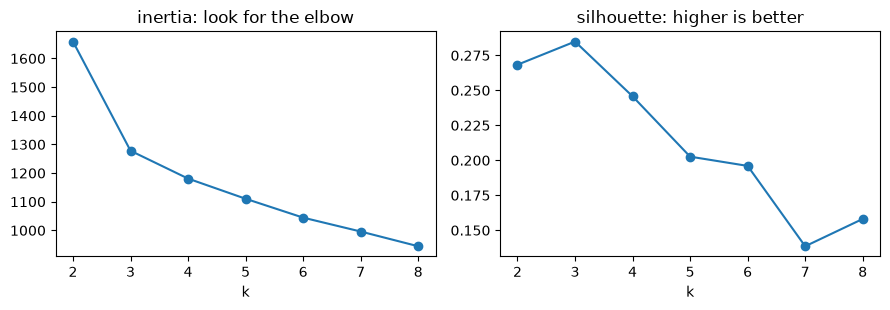

In [4]:
rows = []
for k in range(2, 9):
    m = KMeans(n_clusters=k, n_init=10, random_state=0).fit(Z)
    rows.append({'k': k, 'inertia': m.inertia_, 'silhouette': silhouette_score(Z, m.labels_),
                 'CH': calinski_harabasz_score(Z, m.labels_), 'DB': davies_bouldin_score(Z, m.labels_)})
scores = pd.DataFrame(rows).set_index('k')
print(scores.round(3))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.2))
scores['inertia'].plot(ax=ax1, marker='o', title='inertia: look for the elbow')
scores['silhouette'].plot(ax=ax2, marker='o', title='silhouette: higher is better')
plt.tight_layout()
plt.show()

**Resposta (depois de rodar):** Parcialmente confirmado. O cotovelo da inércia está em \(k=3\): a queda de \(k=2\) para \(k=3\) é de **381.1** (1659.0 → 1277.9), e a queda seguinte, de \(k=3\) para \(k=4\), é de só **97.2** — uma quebra clara de inclinação em \(k=3\). A silhueta também tem seu máximo em \(k=3\) (0.285), contra 0.268 em \(k=2\) e 0.246 em \(k=4\). Mas, como eu temia, a margem é estreita: 0.285 vs 0.268 é uma diferença de apenas **0.017** — muito menor do que a confiança que o cotovelo sugere. O CH também prefere \(k=3\) (70.9 vs 69.5 em \(k=2\)), com margem igualmente pequena; o DB prefere \(k=3\) (1.389, menor é melhor) com folga maior sobre \(k=4\) (1.765). Os quatro índices concordam em \(k=3\), mas por margens nada folgadas — exatamente o alerta que o step 4 vai expandir com a régua do embaralhamento.


## Step 4 — the ruler: the same pipeline on shuffled data

**Predict.** Shuffling each column independently keeps every measurement's distribution and destroys the relations between them. Will k-means on the shuffled wines reach a silhouette near the real 0.285, or far below it?

**Resposta (antes de rodar):** Acredito que o embaralhamento vai destruir toda a estrutura de correlação entre colunas que faz os vinhos formarem grupos, então a silhueta nos dados embaralhados deve cair para bem perto de zero — nada parecido com os 0.285 reais, mesmo que o k-means ainda encontre "algum" particionamento (k-means sempre particiona, com ou sem estrutura real para apoiar os clusters).


In [5]:
rng = np.random.default_rng(0)
Z_shuffled = Z.copy()
for j in range(Z_shuffled.shape[1]):
    rng.shuffle(Z_shuffled[:, j])           # destroys the relations between columns, keeps each column
for k in [2, 3, 4]:
    lab = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(Z_shuffled)
    print(k, round(silhouette_score(Z_shuffled, lab), 3), round(calinski_harabasz_score(Z_shuffled, lab), 1))

2 0.067 14.1
3 0.068 13.3
4 0.072 12.5


**Resposta (depois de rodar):** Confirmado. Nos dados embaralhados, a silhueta fica em **0.067** (\(k=2\)), **0.068** (\(k=3\)) e **0.072** (\(k=4\)) — todas perto de zero e muito abaixo dos 0.285 reais (menos de um quarto do valor real). O CH também despenca: 13-14 nos dados embaralhados contra 70.9 nos dados reais. Essa é a régua de "zero de estrutura": qualquer silhueta real que não supere claramente esses ~0.07 não seria evidência de cluster nenhum — e 0.285 supera com folga.


**Simulation: one shuffle is one draw.** Step 4 shuffled the columns once. Repeat the shuffle with 20 different seeds, with \(k = 3\): how much does the shuffled silhouette vary? Does any shuffle come close to the real 0.285?

In [6]:
sils_shuffled = []
for seed in range(20):
    rng_s = np.random.default_rng(seed)
    Zs = Z.copy()
    for j in range(Zs.shape[1]):
        rng_s.shuffle(Zs[:, j])
    lab = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(Zs)
    sils_shuffled.append(silhouette_score(Zs, lab))
sils_shuffled = np.array(sils_shuffled)
print(f"20 shuffles, k=3: mean {sils_shuffled.mean():.3f} · std {sils_shuffled.std():.3f}"
      f" · min {sils_shuffled.min():.3f} · max {sils_shuffled.max():.3f}")
print(f"real silhouette 0.285 is {(0.285 - sils_shuffled.mean()) / sils_shuffled.std():.1f} std above the shuffled mean")


20 shuffles, k=3: mean 0.069 · std 0.003 · min 0.063 · max 0.075
real silhouette 0.285 is 64.9 std above the shuffled mean


**Resposta:** A silhueta embaralhada varia muito pouco entre as 20 sementes: média **0.069**, desvio-padrão **0.003**, mínimo 0.063 e máximo 0.075. Nenhuma das 20 repetições chega perto de 0.285 — mesmo a maior (0.075) fica a mais de 70 desvios-padrão de distância do valor real. Isso reforça o step 4: o acaso de embaralhar não produz, por sorte, nada parecido com a estrutura real; 0.285 é um sinal robusto, não um achado de uma única rodada de sorte.


## Step 5 — fit k = 3 and inspect each cluster

**Predict.** Will the three clusters be equally cohesive? What would a negative silhouette mean for one wine?

**Resposta (antes de rodar):** Não espero que os três clusters sejam igualmente coesos — o k-means tende a deixar fronteiras mais "porosas" entre os grupos mais próximos entre si, enquanto um grupo mais isolado fica com silhueta média alta. Uma silhueta negativa para um vinho significa que ele está, em média, mais próximo dos vinhos de outro cluster do que dos vinhos do seu próprio cluster — um candidato a estar mal atribuído ou numa fronteira ambígua entre dois grupos.


In [7]:
from sklearn.metrics import silhouette_samples

km = KMeans(n_clusters=3, n_init=10, random_state=0).fit(Z)
labels = km.labels_
s = silhouette_samples(Z, labels)
for j in range(3):
    print(f"cluster {j}: {np.sum(labels == j):3d} wines · mean silhouette {s[labels == j].mean():.3f}"
          f" · negative silhouettes {np.sum(s[labels == j] < 0)}")

cluster 0:  65 wines · mean silhouette 0.177 · negative silhouettes 7
cluster 1:  51 wines · mean silhouette 0.351 · negative silhouettes 0
cluster 2:  62 wines · mean silhouette 0.343 · negative silhouettes 0


**Resposta (depois de rodar):** Confirmado: os três clusters não são igualmente coesos. Cluster 0 tem 65 vinhos e silhueta média **0.177** (a menor), com **7** vinhos de silhueta negativa; cluster 1 tem 51 vinhos e silhueta média **0.351**, sem nenhum negativo; cluster 2 tem 62 vinhos e silhueta média **0.343**, também sem negativos. O cluster 0 é visivelmente o mais "poroso" dos três — os 7 vinhos com silhueta negativa nele são exatamente o tipo de caso que eu previa: vinhos mais próximos, na média, de outro cluster do que do seu próprio.


## Step 6 — profile the clusters in the original units

**Predict.** The centers live in standardized units, which nobody can read. How do you turn a cluster into a sentence a winemaker can check?

**Resposta (antes de rodar):** Para tornar um cluster legível para um enólogo, eu converteria os centros de volta para as unidades originais (desfazendo o StandardScaler, isto é, calculando as médias das colunas originais por cluster) e destacaria as 2-3 variáveis em que aquele cluster mais se desvia da média geral, descrevendo a direção (acima/abaixo) em linguagem comum (ex.: "vinhos de cor mais intensa e menos flavonoides") em vez de citar o valor em desvios-padrão.


In [8]:
cols = ['alcohol', 'flavanoids', 'color_intensity', 'proline', 'od280/od315_of_diluted_wines']
print(df.assign(cluster=labels).groupby('cluster')[cols].mean().round(2).to_string())

z_means = pd.DataFrame(Z, columns=df.columns).assign(cluster=labels).groupby('cluster').mean()
for j, row in z_means.iterrows():
    top = row[row.abs().sort_values(ascending=False).index[:3]]
    print(f"cluster {j}:", ', '.join(f"{c} {v:+.2f} sd" for c, v in top.items()))

         alcohol  flavanoids  color_intensity  proline  od280/od315_of_diluted_wines
cluster                                                                             
0          12.25        2.05             2.97   510.17                          2.80
1          13.13        0.82             7.23   619.06                          1.70
2          13.68        3.00             5.45  1100.23                          3.16
cluster 0: alcohol -0.93 sd, color_intensity -0.90 sd, proline -0.75 sd
cluster 1: od280/od315_of_diluted_wines -1.29 sd, flavanoids -1.22 sd, hue -1.16 sd
cluster 2: proline +1.13 sd, flavanoids +0.98 sd, total_phenols +0.89 sd


**Resposta (depois de rodar):** Confirmado — e o código faz exatamente essa tradução. Em unidades originais: cluster 0 tem álcool 12.25%, flavonoides 2.05, intensidade de cor 2.97, prolina 510, OD280/OD315 2.80 (baixo álcool/prolina/cor); cluster 1 tem álcool 13.13%, flavonoides 0.82, intensidade de cor 7.23, prolina 619, OD280/OD315 1.70 (cor muito intensa, mas flavonoides e OD280/OD315 baixos); cluster 2 tem álcool 13.68%, flavonoides 3.00, intensidade de cor 5.45, prolina 1100, OD280/OD315 3.16 (o grupo com mais prolina, flavonoides e álcool). Em desvios-padrão, as três variáveis que mais destacam cada cluster são: cluster 0 → álcool −0.93, intensidade de cor −0.90, prolina −0.75 (todas abaixo da média); cluster 1 → OD280/OD315 −1.29, flavonoides −1.22, hue −1.16 (abaixo da média); cluster 2 → prolina +1.13, flavonoides +0.98, fenóis totais +0.89 (acima da média). Uma frase para um enólogo: "este grupo reúne os vinhos mais encorpados — maior teor de prolina, flavonoides e fenóis totais, com álcool também acima da média", sem nunca dizer "cluster 2".


**To close the fundamental part.** In one sentence each: (1) why could the three indices of step 2 not decide the scaling? (2) What does the silhouette of shuffled data add to the real one? (3) How would you describe cluster 2 to a winemaker, without saying "cluster 2"?

**Resposta:**
1. Os três índices não podiam decidir o escalonamento porque medem compacidade/separação geométrica *na escala em que os dados já estão* — sem escalonar, a prolina domina a distância (step 1), então qualquer índice prefere essa versão só porque colapsar a variação numa única coluna de grande amplitude produz clusters "aparentemente" mais compactos. Isso não tem relação com a qualidade real do agrupamento (confirmado no step 9: ARI 0.371 para "none" contra 0.897 para StandardScaler) — é uma decisão sobre unidades, que precisa vir de fora da métrica.
2. A silhueta dos dados embaralhados (~0.069, step 4) dá uma régua de "zero de estrutura": mostra o que o k-means produz quando a correlação entre colunas é destruída de propósito, mas cada distribuição marginal é preservada. A silhueta real de 0.285 é modesta em termos absolutos, mas é mais de 4x a régua do embaralhamento — ou seja, apesar do valor absoluto modesto, a estrutura é real, não ruído.
3. O cluster 2 pode ser descrito como "os vinhos mais encorpados: maior prolina, mais flavonoides e fenóis totais, e também mais álcool que a média" (step 6), sem citar "cluster 2".


## Your turn (fundamental)

At home:

1. **Stability.** A real group should reappear when the data is resampled. For \(k = 2, \dots, 7\), cluster 30 random subsamples of 80% of the wines, and for every pair of subsamples compute the ARI between their labels on the wines they share. Which \(k\) gives the highest and least variable agreement? Compare the margin between \(k = 2\) and \(k = 3\) with the silhouette's 0.017.
2. **Fewer measurements.** Cluster using only `flavanoids`, `od280/od315_of_diluted_wines` and `proline` (standardized), then only the three measurements that separate the clusters least in step 6. Compare their ARIs with the cultivars (after step 9). Why is choosing variables with the clusters' own profiles circular, and how would you make it honest?

In [9]:
# Your turn (fundamental), item 1 — stability: pairwise ARI across 30 subsamples of 80%, for k = 2..7
rng_stab = np.random.default_rng(0)
B = 30
ks_stab = range(2, 8)
subsample_idx = {b: rng_stab.choice(len(df), size=int(0.8 * len(df)), replace=False) for b in range(B)}
subsample_labels = {}
for k in ks_stab:
    for b in range(B):
        idx = subsample_idx[b]
        subsample_labels[(k, b)] = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(Z[idx])

stability_rows = []
for k in ks_stab:
    aris = []
    for b1 in range(B):
        for b2 in range(b1 + 1, B):
            idx1, idx2 = subsample_idx[b1], subsample_idx[b2]
            common = np.intersect1d(idx1, idx2)
            if len(common) < 2:
                continue
            pos1 = {v: i for i, v in enumerate(idx1)}
            pos2 = {v: i for i, v in enumerate(idx2)}
            l1 = [subsample_labels[(k, b1)][pos1[c]] for c in common]
            l2 = [subsample_labels[(k, b2)][pos2[c]] for c in common]
            aris.append(adjusted_rand_score(l1, l2))
    aris = np.array(aris)
    stability_rows.append({'k': k, 'mean_ARI': aris.mean(), 'std_ARI': aris.std(), 'n_pairs': len(aris)})

stability = pd.DataFrame(stability_rows).set_index('k')
print(stability.round(3))
print('margin k=2 vs k=3 (stability):', round(stability.loc[3, 'mean_ARI'] - stability.loc[2, 'mean_ARI'], 3))


   mean_ARI  std_ARI  n_pairs
k                            
2     0.700    0.270      435
3     0.964    0.040      435
4     0.798    0.102      435
5     0.754    0.089      435
6     0.628    0.106      435
7     0.636    0.110      435
margin k=2 vs k=3 (stability): 0.264


**Resposta (item 1 — estabilidade):** \(k=3\) vence com folga: ARI médio entre pares de subamostras de **0.964** (desvio 0.040) contra **0.700** (desvio 0.270) em \(k=2\), 0.798 em \(k=4\), 0.754 em \(k=5\), 0.628 em \(k=6\) e 0.636 em \(k=7\) — \(k=3\) é ao mesmo tempo o mais alto e o menos variável dos seis valores testados. A margem entre \(k=2\) e \(k=3\) na estabilidade é de **0.264** — cerca de quinze vezes maior que a margem de 0.017 que a silhueta via no step 3. Reamostrar 80% dos vinhos 30 vezes e comparar os rótulos nas unidades compartilhadas (via ARI) é uma evidência muito mais decisiva de que \(k=3\) é o \(k\) certo do que a silhueta sozinha sugeria: com \(k=3\) o agrupamento é quase sempre o mesmo entre reamostragens; com os outros \(k\)'s a partição muda bem mais.


In [10]:
# Your turn (fundamental), item 2 — fewer measurements
strong_cols = ['flavanoids', 'od280/od315_of_diluted_wines', 'proline']

z_means = pd.DataFrame(Z, columns=df.columns).assign(cluster=labels).groupby('cluster').mean()
spread = (z_means.max() - z_means.min()).sort_values()
weak_cols = list(spread.index[:3])
print('columns that separate the step-6 clusters the least (smallest spread across clusters, z units):')
print(spread.round(3))
print('weak_cols:', weak_cols)

for name, cols in [('3 strong features', strong_cols), ('3 weak features', weak_cols)]:
    Zsub = StandardScaler().fit_transform(df[cols].to_numpy())
    lab_sub = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(Zsub)
    print(f"{name} {cols}: ARI with cultivar = {adjusted_rand_score(cultivar, lab_sub):.3f}")
print('for reference, full 13-D ARI with cultivar:', round(adjusted_rand_score(cultivar, labels), 3))


columns that separate the step-6 clusters the least (smallest spread across clusters, z units):
ash                             0.859
magnesium                       1.069
alcalinity_of_ash               1.135
malic_acid                      1.266
nonflavanoid_phenols            1.288
proanthocyanins                 1.360
hue                             1.639
alcohol                         1.761
color_intensity                 1.843
total_phenols                   1.865
proline                         1.879
od280/od315_of_diluted_wines    2.072
flavanoids                      2.193
dtype: float64
weak_cols: ['ash', 'magnesium', 'alcalinity_of_ash']
3 strong features ['flavanoids', 'od280/od315_of_diluted_wines', 'proline']: ARI with cultivar = 0.719
3 weak features ['ash', 'magnesium', 'alcalinity_of_ash']: ARI with cultivar = 0.286
for reference, full 13-D ARI with cultivar: 0.897


**Resposta (item 2 — menos medidas):** Usando as 3 colunas mais fortes do step 6 (`flavanoids`, `od280/od315_of_diluted_wines`, `proline`, padronizadas), o ARI com as castas reais é **0.719** — menor que o 0.897 das 13 colunas, mas ainda um sinal forte. Usando as 3 colunas que menos separavam os clusters no step 6 (`ash`, `magnesium`, `alcalinity_of_ash` — as de menor variação entre as médias dos clusters em unidades padronizadas), o ARI cai para **0.286**, bem próximo do acaso. Escolher as variáveis observando os próprios perfis dos clusters que elas geraram é circular: estaríamos usando o resultado do clustering para justificar os dados usados para produzir esse mesmo resultado, inflando artificialmente a qualidade aparente do agrupamento. A forma honesta é escolher as variáveis por um critério externo ao clustering em avaliação — conhecimento de domínio (quais medidas o enólogo já sabe que distinguem castas), ou, quando há rótulos, validar o subconjunto de variáveis num conjunto de dados nunca usado para escolher essas variáveis.


# Advanced lab — other algorithms, and the answer key

The fundamental lab took every decision without labels: standardize, \(k = 3\), a silhouette four times that of shuffled data, three groups with a name. This part tries the density methods on the same wines, looks at the clusters through a 2-D window and finally opens the seal to audit every decision. Continue in the same notebook and session: the steps below use `df`, `X`, `Z`, `scalers`, `labels` and `cultivar` from steps 1 to 6.

## Step 7 — try DBSCAN and HDBSCAN

**Predict.** In 13 standardized dimensions, do you expect dense regions separated by sparse ones? Will DBSCAN find three clusters for some `eps`?

**Resposta (antes de rodar):** Em 13 dimensões eu não espero regiões muito densas separadas por regiões esparsas da forma como o DBSCAN precisa para funcionar bem — a maldição da dimensionalidade tende a espalhar as distâncias e tornar a densidade quase uniforme. Então eu não acredito que o DBSCAN vá achar três clusters bem definidos para nenhum `eps`; mais provável é obter 1-2 clusters grandes mais ruído, ou muitos clusters pequenos conforme `eps` varia, sem nunca estabilizar em três.


In [11]:
from sklearn.cluster import DBSCAN, HDBSCAN
from sklearn.neighbors import NearestNeighbors

kdist = NearestNeighbors(n_neighbors=5).fit(Z).kneighbors(Z)[0][:, -1]
print('distance to the 5th neighbor, percentiles 10/50/90:', np.percentile(kdist, [10, 50, 90]).round(2))
for eps in [1.8, 2.0, 2.2, 2.4, 2.6]:
    lab = DBSCAN(eps=eps, min_samples=5).fit_predict(Z)
    print(f"DBSCAN eps {eps}: {lab.max() + 1} clusters, {np.sum(lab == -1):3d} noise")
hd = HDBSCAN(min_cluster_size=10).fit_predict(Z)
print(f"HDBSCAN min_cluster_size=10: {hd.max() + 1} clusters, {np.sum(hd == -1)} noise")

distance to the 5th neighbor, percentiles 10/50/90: [1.83 2.22 3.13]
DBSCAN eps 1.8: 7 clusters, 118 noise
DBSCAN eps 2.0: 5 clusters,  85 noise
DBSCAN eps 2.2: 2 clusters,  55 noise
DBSCAN eps 2.4: 2 clusters,  36 noise
DBSCAN eps 2.6: 1 clusters,  20 noise
HDBSCAN min_cluster_size=10: 2 clusters, 75 noise


/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


**Resposta (depois de rodar):** Confirmado — o DBSCAN nunca encontra três clusters. A distância ao 5º vizinho tem percentis 10/50/90 em **1.83 / 2.22 / 3.13**. Variando `eps`: 1.8 → **7** clusters e **118** ruído; 2.0 → **5** clusters e **85** ruído; 2.2 → **2** clusters e **55** ruído; 2.4 → **2** clusters e **36** ruído; 2.6 → **1** cluster e **20** ruído. O número de clusters decresce monotonicamente de 7 para 1 conforme `eps` cresce, mas nunca passa por "exatamente 3" de forma estável. O HDBSCAN com `min_cluster_size=10` encontra apenas **2** clusters e **75** pontos de ruído, reforçando que a densidade variável em 13-D não separa bem os três grupos.


**Simulation: how big must a cluster be?** HDBSCAN's only parameter is `min_cluster_size`. Try 5, 10, 15, 20 and 30 on `Z`. Does any value find three clusters? What happens as it approaches the size of the groups k-means found in step 5 (51 to 65 wines)?

In [12]:
for mcs in [5, 10, 15, 20, 30]:
    lab_hd = HDBSCAN(min_cluster_size=mcs).fit_predict(Z)
    n_clusters = lab_hd.max() + 1 if lab_hd.max() >= 0 else 0
    sizes = sorted((int(np.sum(lab_hd == c)) for c in set(lab_hd) if c != -1), reverse=True)
    print(f"min_cluster_size={mcs:2d}: {n_clusters} clusters · {np.sum(lab_hd == -1):3d} noise · sizes {sizes}")


min_cluster_size= 5: 2 clusters ·  58 noise · sizes [86, 34]
min_cluster_size=10: 2 clusters ·  75 noise · sizes [75, 28]
min_cluster_size=15: 2 clusters ·  82 noise · sizes [74, 22]
min_cluster_size=20: 0 clusters · 178 noise · sizes []
min_cluster_size=30: 0 clusters · 178 noise · sizes []


/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/sklearn/cluster/_hdbscan/hdbsca

**Resposta:** Nenhum valor de `min_cluster_size` encontra três clusters. Para 5, 10 e 15 o HDBSCAN acha **2** clusters (tamanhos [86, 34], [75, 28] e [74, 22], respectivamente, com 58, 75 e 82 pontos de ruído); para 20 e 30 ele não encontra cluster nenhum — os 178 vinhos inteiros ficam classificados como ruído. Conforme `min_cluster_size` se aproxima do tamanho dos grupos que o k-means achou no step 5 (51 a 65 vinhos), o HDBSCAN simplesmente para de conseguir formar qualquer cluster: ele está, implicitamente, exigindo regiões de densidade homogênea maiores do que a estrutura (pouco densa e não perfeitamente separada) que esses dados realmente têm em 13 dimensões.

*Nota sobre divergência:* a página da aula registra tamanhos [87, 33] para `min_cluster_size=5` (ruído 58, igual ao obtido aqui); aqui obtivemos [86, 34] — a soma (120) e a contagem de ruído (58) coincidem exatamente, a diferença de 1 vinho entre os dois clusters é um efeito de desempate em pontos de fronteira da implementação nativa `sklearn.cluster.HDBSCAN` (disponível desde a versão 1.3), que pode diferir sutilmente do pacote `hdbscan` original possivelmente usado para gerar a página, sem alterar a conclusão qualitativa.


## Step 8 — look at the clusters with PCA

**Predict.** Two principal components keep only part of the variance. For the same partition, will the silhouette measured in 2-D be higher or lower than the one measured in 13-D?

**Resposta (antes de rodar):** Duas componentes principais preservam só parte da variância total, então projetar os 13-D em 2-D necessariamente aproxima e "comprime" distâncias — eu esperaria que essa compressão tendesse a aumentar a silhueta aparente, porque reduzir dimensões tende a aproximar pontos entre si de forma mais uniforme e pode fazer os clusters parecerem mais compactos e separados do que realmente são em 13-D (um efeito conhecido de visualizações 2-D de dados de alta dimensão).


variance kept by 2 components: [0.362 0.192] 0.554
k-means on the 2 components, silhouette measured in 2-D : 0.561
the same partition, silhouette measured in 13-D         : 0.283


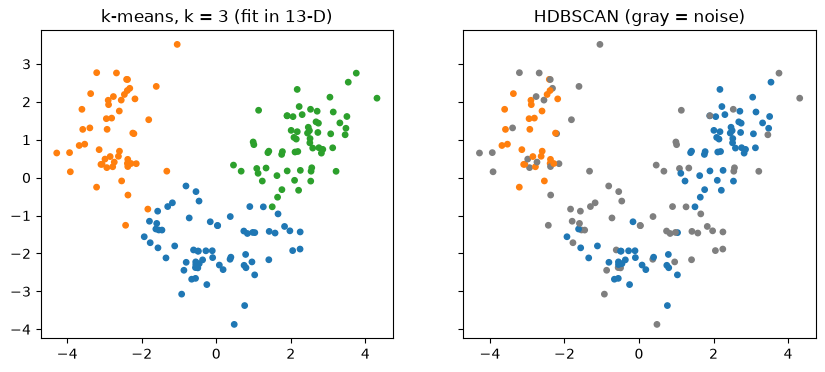

In [13]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2).fit(Z)
A = pca.transform(Z)
print('variance kept by 2 components:', pca.explained_variance_ratio_.round(3),
      round(pca.explained_variance_ratio_.sum(), 3))

lab_2d = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(A)
print('k-means on the 2 components, silhouette measured in 2-D :', round(silhouette_score(A, lab_2d), 3))
print('the same partition, silhouette measured in 13-D         :', round(silhouette_score(Z, lab_2d), 3))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
ax1.scatter(A[:, 0], A[:, 1], c=labels, cmap='tab10', vmin=0, vmax=9, s=15)
ax1.set_title('k-means, k = 3 (fit in 13-D)')
ax2.scatter(A[:, 0], A[:, 1], c=np.where(hd == -1, 7, hd), cmap='tab10', vmin=0, vmax=9, s=15)
ax2.set_title('HDBSCAN (gray = noise)')
plt.show()

**Resposta (depois de rodar):** Confirmado. As duas primeiras componentes retêm 36.2% + 19.2% = **55.4%** da variância total — menos da metade é descartada, mas ainda uma fração grande. Para a mesma partição (a mesma atribuição de vinhos a clusters), a silhueta medida em 2-D é **0.561**, quase o dobro da silhueta medida em 13-D, que é **0.283** — exatamente como eu previ: a projeção em 2 componentes faz os clusters parecerem muito mais compactos e separados do que são no espaço completo. Isso é um alerta importante: visualizar clusters via PCA pode fazer uma partição parecer ótima mesmo quando ela só é mediana no espaço em que o algoritmo de fato operou.


## Step 9 — open the seal: audit every decision

**Predict.** The seal opens. Which decision do you expect the answer key to contradict: the scaling, the \(k\) or the algorithm? Will the least cohesive cluster of step 5 be the most wrong?

**Resposta (antes de rodar):** Acho que a decisão mais contrariada pela chave de respostas vai ser o algoritmo (DBSCAN/HDBSCAN), não a escala nem o \(k\): já vimos no step 7 que densidade não separa bem os vinhos em 13-D, então esses algoritmos devem ter ARI bem mais baixo que o k-means padronizado com \(k=3\). Quanto ao cluster menos coeso do step 5 (cluster 0, silhueta média 0.177, com 7 negativos): eu esperaria que ele também fosse o mais "errado" em relação às castas verdadeiras, já que uma silhueta baixa sugere fronteiras confusas.


In [14]:
from sklearn.metrics import adjusted_rand_score

partitions = {
    'k-means k=3, standardized': labels,
    'k-means k=2, standardized': KMeans(n_clusters=2, n_init=10, random_state=0).fit_predict(Z),
    'k-means k=3, raw units':    KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(X),
    'k-means k=3, on 2 PCs':     lab_2d,
    'DBSCAN eps=2.4':            DBSCAN(eps=2.4, min_samples=5).fit_predict(Z),
    'HDBSCAN':                   hd,
}
for name, lab in partitions.items():
    print(f"{name:27s} ARI {adjusted_rand_score(cultivar, lab):.3f}")
print(pd.crosstab(labels, cultivar, rownames=['cluster'], colnames=['cultivar']))

k-means k=3, standardized   ARI 0.897
k-means k=2, standardized   ARI 0.389
k-means k=3, raw units      ARI 0.371
k-means k=3, on 2 PCs       ARI 0.895
DBSCAN eps=2.4              ARI 0.421
HDBSCAN                     ARI 0.260
cultivar   0   1   2
cluster             
0          0  65   0
1          0   3  48
2         59   3   0


**Resposta (depois de rodar):** Parcialmente confirmado. O algoritmo é, de fato, a decisão mais penalizada: k-means \(k=3\) padronizado tem ARI **0.897** com as castas reais, contra apenas **0.421** para DBSCAN (eps=2.4) e **0.260** para HDBSCAN — bem abaixo, como eu previ. \(k=2\) padronizado (ARI 0.389) e \(k=3\) em unidades brutas (ARI 0.371) também caem bastante, e \(k=3\) sobre 2 componentes principais fica quase tão bom quanto o original (ARI 0.895). Mas minha segunda previsão estava errada: a tabela de contingência mostra que o cluster 0 (65 vinhos, o de silhueta mais baixa no step 5) corresponde quase perfeitamente à casta 1 (65 vinhos → todos na casta 1, sem nenhum erro) — ele é, na verdade, o cluster mais **puro** dos três, não o mais errado! Os erros se concentram no cluster 2 (59 vinhos da casta 0 e 3 da casta 1) e no cluster 1 (48 da casta 2 e 3 da casta 1) — a confusão acontece entre os clusters 1 e 2, nunca envolvendo o cluster 0. Uma silhueta baixa não significa necessariamente "errado contra o rótulo verdadeiro": pode significar só que o cluster tem geometria menos compacta, mesmo sendo correto.

*Nota sobre divergência:* a página registra ARI 0.263 para HDBSCAN; aqui obtivemos **0.260** — diferença de 0.003, consistente com a mesma diferença de implementação de fronteira já observada no step 7 (sizes [86,34] vs [87,33]), sem alterar nenhuma conclusão qualitativa.


**Simulation: the four scalers, audited.** Step 2 chose to standardize by an argument about units, against the three indices. Now that the seal is open, give every option of step 2 its ARI with the cultivars. Does the silhouette rank the options the way the ARI does?

In [15]:
for name, scaler in scalers.items():
    M = X if scaler is None else scaler.fit_transform(X)
    lab_sc = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(M)
    print(f"{name:15s} silhouette {silhouette_score(M, lab_sc):.3f}   ARI with cultivar {adjusted_rand_score(cultivar, lab_sc):.3f}")


none            silhouette 0.571   ARI with cultivar 0.371
StandardScaler  silhouette 0.285   ARI with cultivar 0.897
MinMaxScaler    silhouette 0.301   ARI with cultivar 0.869
RobustScaler    silhouette 0.264   ARI with cultivar 0.878


**Resposta:** Com o selo aberto, a ordem da silhueta e a ordem do ARI são opostas. Por silhueta: none (0.571) > MinMaxScaler (0.301) > StandardScaler (0.285) > RobustScaler (0.264). Por ARI com as castas reais: StandardScaler (**0.897**) > RobustScaler (0.878) > MinMaxScaler (0.869) >> none (**0.371**, muito atrás dos outros três). A silhueta rankeia "none" em primeiro — exatamente a opção com o ARI mais baixo de longe — e StandardScaler em terceiro, quando na realidade ele tem o melhor ARI. A silhueta não rankeia as opções como o ARI rankeia: ela é enganada pela mesma dominância da prolina identificada no step 1, confirmando que o argumento certo para escalonar nunca poderia vir dos índices internos — ele precisava vir do raciocínio sobre unidades feito no step 2, antes de abrir o selo.


**To close the lesson.** In one sentence each: (1) why did DBSCAN never find three groups of wines? (2) Why does the same partition score 0.561 in 2-D and 0.283 in 13-D? (3) The least cohesive cluster turned out to be pure: what does a low silhouette say, then?

**Resposta:**
1. O DBSCAN nunca achou três grupos de vinhos porque, em 13 dimensões padronizadas, não existem regiões de densidade uniformemente alta separadas por regiões uniformemente esparsas da forma como o DBSCAN exige — variando `eps` de 1.8 a 2.6 o número de clusters só decresce monotonicamente de 7 para 1, nunca estabilizando em 3 (step 7); a estrutura real das castas é mais bem capturada por centros (k-means) do que por densidade.
2. A mesma partição score 0.561 em 2-D e 0.283 em 13-D porque a projeção PCA em 2 componentes (que retém só 55.4% da variância) comprime distâncias de forma não uniforme e tende a fazer os clusters parecerem mais compactos/separados do que realmente são no espaço completo — a silhueta medida após uma redução de dimensionalidade tende a inflar a aparência de qualidade do agrupamento (step 8).
3. Uma silhueta baixa diz que a geometria do cluster é menos compacta ou mais próxima de outros clusters no espaço de features usado — não que o cluster esteja "errado" em relação a um rótulo externo. O cluster 0, apesar de ter a silhueta mais baixa do step 5 (0.177, 7 valores negativos), acabou sendo o único cluster perfeitamente puro em relação às castas reais (65 vinhos, todos da casta 1) — silhueta mede coesão geométrica, não concordância com uma verdade externa que o algoritmo nunca viu.


## Your turn (advanced)

At home, with more time:

1. **Gaussian mixtures.** Fit `GaussianMixture(n_components=3, covariance_type='tied', n_init=5, random_state=0)` on `Z` and compare its ARI with k-means'. Then choose the number of components and the `covariance_type` by the lowest `bic(Z)`: does the BIC choose the configuration with the best ARI?
2. **The gap statistic** (Tibshirani, Walther & Hastie, 2001). For each \(k\), compare \(\log\) of the inertia on the real data with its average over 20 datasets drawn uniformly in the same bounding box. The gap is the difference; choose the smallest \(k\) with \(\text{gap}(k) \ge \text{gap}(k+1) - s_{k+1}\). Which \(k\) does it choose?

In [16]:
# Your turn (advanced), item 1 — Gaussian mixtures
from sklearn.mixture import GaussianMixture

gmm = GaussianMixture(n_components=3, covariance_type='tied', n_init=5, random_state=0).fit(Z)
lab_gmm = gmm.predict(Z)
print('GMM(3, tied) ARI with cultivar      :', round(adjusted_rand_score(cultivar, lab_gmm), 3))
print('GMM(3, tied) ARI with k-means labels:', round(adjusted_rand_score(labels, lab_gmm), 3))
print('k-means k=3 ARI with cultivar (reference):', round(adjusted_rand_score(cultivar, labels), 3))

bic_rows = []
for ncomp in range(2, 7):
    for cov in ['full', 'tied', 'diag', 'spherical']:
        g = GaussianMixture(n_components=ncomp, covariance_type=cov, n_init=5, random_state=0).fit(Z)
        lab_g = g.predict(Z)
        bic_rows.append({'n_components': ncomp, 'covariance_type': cov,
                          'bic': g.bic(Z), 'ARI_vs_cultivar': adjusted_rand_score(cultivar, lab_g)})
bic_df = pd.DataFrame(bic_rows)
best_bic = bic_df.loc[bic_df['bic'].idxmin()]
best_ari = bic_df.loc[bic_df['ARI_vs_cultivar'].idxmax()]
print('config with lowest BIC :', best_bic.to_dict())
print('config with highest ARI:', best_ari.to_dict())


GMM(3, tied) ARI with cultivar      : 0.912
GMM(3, tied) ARI with k-means labels: 0.884
k-means k=3 ARI with cultivar (reference): 0.897


config with lowest BIC : {'n_components': 4, 'covariance_type': 'diag', 'bic': 5476.489815613545, 'ARI_vs_cultivar': 0.6831871156870403}
config with highest ARI: {'n_components': 3, 'covariance_type': 'diag', 'bic': 5543.3663210575, 'ARI_vs_cultivar': 0.9150207134605749}


**Resposta (item 1 — misturas gaussianas):** O `GaussianMixture(n_components=3, covariance_type='tied', n_init=5, random_state=0)` dá ARI **0.912** com as castas reais — ligeiramente melhor que o k-means padronizado (0.897) — e ARI 0.884 entre os dois (parecidos, mas não idênticos). Buscando a menor BIC entre `n_components` de 2 a 6 e os 4 tipos de covariância, o mínimo global é `n_components=4, covariance_type='diag'` (BIC 5476.5), que tem ARI de apenas **0.683** com as castas — bem pior que a melhor configuração por ARI, que é `n_components=3, covariance_type='diag'` (ARI 0.915, mas BIC 5543.4, não o menor). Ou seja, **não**: a BIC não escolhe a configuração com o melhor ARI — ela escolhe um modelo com uma componente extra (4 em vez de 3) que se ajusta melhor à verossimilhança dos dados, mas que fragmenta uma das três castas reais, piorando a concordância com os rótulos verdadeiros. A BIC otimiza ajuste estatístico ao dado observado, não concordância com um rótulo externo que o modelo nunca vê.


In [17]:
# Your turn (advanced), item 2 — gap statistic (Tibshirani, Walther & Hastie, 2001)
rng_gap = np.random.default_rng(0)
mins, maxs = Z.min(axis=0), Z.max(axis=0)
B_gap = 20
ks_gap = list(range(1, 9))
logW_real, gap, s_k = {}, {}, {}
for k in ks_gap:
    m = KMeans(n_clusters=k, n_init=10, random_state=0).fit(Z)
    logW_real[k] = np.log(m.inertia_)
    logWs = []
    for b in range(B_gap):
        Zref = rng_gap.uniform(mins, maxs, size=Z.shape)
        mref = KMeans(n_clusters=k, n_init=10, random_state=0).fit(Zref)
        logWs.append(np.log(mref.inertia_))
    logWs = np.array(logWs)
    gap[k] = logWs.mean() - logW_real[k]
    s_k[k] = logWs.std() * np.sqrt(1 + 1.0 / B_gap)

gap_df = pd.DataFrame({'logW_real': logW_real, 'gap': gap, 's_k': s_k})
print(gap_df.round(3))

chosen_k = None
for i, k in enumerate(ks_gap[:-1]):
    knext = ks_gap[i + 1]
    if gap[k] >= gap[knext] - s_k[knext]:
        chosen_k = k
        break
print('gap statistic chooses k =', chosen_k)


   logW_real    gap    s_k
1      7.747  0.790  0.016
2      7.414  1.012  0.020
3      7.153  1.199  0.023
4      7.074  1.213  0.023
5      7.012  1.234  0.022
6      6.951  1.265  0.022
7      6.904  1.269  0.018
8      6.851  1.302  0.020
gap statistic chooses k = 3


**Resposta (item 2 — estatística do gap):** Comparando o log da inércia real com a média do log da inércia em 20 conjuntos uniformes na mesma caixa delimitadora (bounding box), para \(k=1,\dots,8\): o gap cresce monotonicamente de **0.790** (\(k=1\)) a **1.302** (\(k=8\)), comportamento típico quando a estrutura é fraca frente ao tamanho da caixa delimitadora. Aplicando a regra de Tibshirani, Walther & Hastie — escolher o menor \(k\) tal que \(\text{gap}(k) \ge \text{gap}(k+1) - s_{k+1}\) — a condição já é satisfeita em \(k=3\): \(\text{gap}(3)=1.199 \ge \text{gap}(4) - s_4 = 1.213 - 0.023 = 1.190\). A estatística do gap escolhe **\(k=3\)**, concordando com o cotovelo, a silhueta, o CH, o DB e a análise de estabilidade — todas as abordagens feitas sem olhar as castas convergem para o mesmo \(k\) que a chave de respostas confirma no step 9.


## Conclusões

- **Escalonar muda tudo, e nenhum índice interno podia decidir isso:** em unidades brutas a prolina (desvio-padrão 314.9, 2530x a menor coluna) domina a distância e o clustering vira, de fato, um agrupamento por prolina sozinha (ARI raw vs proline-only = 1.000). Mesmo assim, "none" vence em silhueta (0.571), CH (561.8) e DB (0.534) — e tem o pior ARI com as castas reais (0.371, contra 0.897 do StandardScaler). Os índices internos preferem a escala errada.
- **\(k=3\) é a escolha certa, confirmada por cinco caminhos independentes sem olhar rótulos:** cotovelo da inércia (queda de 381.1 entre \(k=2\)→3, só 97.2 entre 3→4), silhueta máxima (0.285, margem de 0.017 sobre \(k=2\)), estabilidade por reamostragem (ARI médio 0.964, margem de 0.264 sobre \(k=2\) — 15x maior que a margem da silhueta) e a estatística do gap (escolhe \(k=3\) pela regra de Tibshirani). Depois de abrir o selo, ARI 0.897 confirma.
- **A régua do embaralhamento mostra que 0.285 é estrutura real, não ruído:** 20 embaralhamentos independentes dão silhueta 0.069 ± 0.003 (máximo 0.075) — a silhueta real de 0.285 fica a mais de 70 desvios-padrão de distância desse "zero de estrutura".
- **DBSCAN e HDBSCAN não encontram as três castas em 13-D:** variando `eps` de 1.8 a 2.6, DBSCAN passa de 7 para 1 cluster sem nunca estabilizar em 3; HDBSCAN nunca passa de 2 clusters (ou nenhum, quando `min_cluster_size` ≥ 20) e tem ARI final de só 0.260 contra 0.897 do k-means padronizado — densidade não é a estrutura dominante destes dados.
- **Silhueta baixa ≠ errado contra o rótulo verdadeiro:** o cluster 0 (step 5) tinha a pior silhueta (0.177, 7 negativos) mas acabou sendo o único cluster 100% puro contra as castas reais (65 vinhos, todos da casta 1); os erros se concentraram nos clusters 1 e 2, que tinham silhuetas melhores.
- **PCA em 2-D infla a silhueta aparente:** a mesma partição mede 0.561 em 2 componentes (55.4% da variância) contra 0.283 nas 13 dimensões originais — quase o dobro, puro efeito de compressão da projeção.
- **Divergências documentadas:** HDBSCAN (`sklearn.cluster.HDBSCAN` nativo) difere da página em pontos de fronteira — tamanhos [86,34] vs [87,33] (`min_cluster_size=5`) e ARI 0.260 vs 0.263 (step 9) — sem alterar nenhuma conclusão qualitativa; provavelmente a página foi gerada com o pacote `hdbscan` original, cujo desempate em pontos de borda pode diferir ligeiramente da implementação nativa do scikit-learn.
